## 四方ZrO2 不同参数优化方法 5个轨道

In [1]:
import numpy as np
import mindspore as ms
from mindspore import context, nn, Parameter, Tensor
from mindspore.common.initializer import initializer
import matplotlib.pyplot as plt


from openfermion.chem import MolecularData
from openfermionpyscf import run_pyscf
from mindquantum.core.gates import X
from mindquantum.core.circuit import Circuit
from mindquantum.core.operators import Hamiltonian
from mindquantum.simulator import Simulator
from mindquantum.algorithm.nisq import generate_uccsd
import mindspore as ms

import numpy as np
import mindspore as ms
from mindquantum import *
import matplotlib.pyplot as plt
from mindspore import context, nn, Parameter, Tensor
from mindspore.common.initializer import initializer

In [2]:
from openfermion.chem import MolecularData
from openfermionpyscf import run_pyscf
from mindquantum.core.gates import X
from mindquantum.core.circuit import Circuit
from mindquantum.core.operators import Hamiltonian
from mindquantum.simulator import Simulator
from mindquantum.algorithm.nisq import generate_uccsd
import mindspore as ms

from openfermion.transforms import get_fermion_operator, jordan_wigner
from openfermion.linalg import get_ground_state, get_sparse_operator
import numpy
import scipy
import scipy.linalg

from mindquantum.algorithm.nisq import Transform
from mindquantum.algorithm.nisq import get_qubit_hamiltonian
from mindquantum.algorithm.nisq import uccsd_singlet_generator, uccsd_singlet_get_packed_amplitudes
from mindquantum.core.operators import TimeEvolution, count_qubits
from mindquantum.framework import MQAnsatzOnlyLayer


import itertools
from collections import OrderedDict

import numpy as np

from mindquantum.core.circuit import Circuit, decompose_single_term_time_evolution
from mindquantum.core.operators import FermionOperator, down_index, up_index
from mindquantum.third_party.interaction_operator import InteractionOperator
from mindquantum.utils.type_value_check import _require_package

from mindquantum.algorithm.nisq.chem.transform import Transform
from mindquantum.algorithm.nisq.chem.uccsd import _transform2pauli, _pauli2circuit

import random
import matplotlib.pyplot as plt

ms.set_context(mode=ms.PYNATIVE_MODE, device_target="CPU")

[WARNING] ME(1081936:128677219631104,MainProcess):2025-06-12-14:28:32.979.000 [mindspore/context.py:1335] For 'context.set_context', the parameter 'device_target' will be deprecated and removed in a future version. Please use the api mindspore.set_device() instead.


In [3]:
def _para_uccsd_singlet_generator(mol, threshold=0, n_qubits=0, n_electrons=0):  # pylint: disable=too-many-locals,too-many-statements
    """
    Generate a uccsd quantum circuit.

    Args:
        mol (molecular): A hdf5 molecular file generated by HiQ Fermion.
        threshold (float, optional): A threshold of parameters. If the absolute value of parameter is
            lower than the threshold, than we will not update it in VQE
            algorithm. Default: ``0``.
    """
    if n_qubits == 0:
        n_qubits = mol.n_qubits
        n_electrons = mol.n_electrons
    params = {}
    if n_qubits % 2 != 0:
        raise ValueError('The total number of spin-orbitals should be even.')
    out = []
    out_tmp = []
    n_spatial_orbitals = n_qubits // 2
    n_occupied = int(np.ceil(n_electrons / 2))
    n_virtual = n_spatial_orbitals - n_occupied

    # Unpack amplitudes
    n_single_amplitudes = n_occupied * n_virtual
    # Generate excitations
    spin_index_functions = [up_index, down_index]
    # Generate all spin-conserving single and double excitations derived
    # from one spatial occupied-virtual pair
    for i, (p, q) in enumerate(itertools.product(range(n_virtual), range(n_occupied))):  # pylint: disable=invalid-name
        # Get indices of spatial orbitals
        virtual_spatial = n_occupied + p
        occupied_spatial = q
        virtual_up = virtual_spatial * 2
        occupied_up = occupied_spatial * 2
        virtual_down = virtual_spatial * 2 + 1
        occupied_down = occupied_spatial * 2 + 1
        single_amps = mol.ccsd_single_amps[virtual_up, occupied_up]
        double1_amps = mol.ccsd_double_amps[virtual_up, occupied_up, virtual_down, occupied_down]
        single_amps_name = 'p' + str(i)
        double1_amps_name = 'p' + str(i + n_single_amplitudes)

        for spin in range(2):
            # Get the functions which map a spatial orbital index to a
            # spin orbital index
            this_index = spin_index_functions[spin]
            other_index = spin_index_functions[1 - spin]

            # Get indices of spin orbitals
            virtual_this = this_index(virtual_spatial)
            virtual_other = other_index(virtual_spatial)
            occupied_this = this_index(occupied_spatial)
            occupied_other = other_index(occupied_spatial)

            # Generate single excitations
            if abs(single_amps) > threshold:
                params[single_amps_name] = single_amps
                fermion_ops1 = FermionOperator(((occupied_this, 1), (virtual_this, 0)), 1)
                fermion_ops2 = FermionOperator(((virtual_this, 1), (occupied_this, 0)), 1)
                out.append([fermion_ops1 - fermion_ops2, single_amps_name])

            # Generate double excitation
            if abs(double1_amps) > threshold:
                params[double1_amps_name] = double1_amps
                fermion_ops1 = FermionOperator(
                    ((virtual_this, 1), (occupied_this, 0), (virtual_other, 1), (occupied_other, 0)), 1
                )
                fermion_ops2 = FermionOperator(
                    ((occupied_other, 1), (virtual_other, 0), (occupied_this, 1), (virtual_this, 0)), 1
                )
                out.append([fermion_ops1 - fermion_ops2, double1_amps_name])
    out.extend(out_tmp)
    out_tmp = []
    # Generate all spin-conserving double excitations derived
    # from two spatial occupied-virtual pairs
    for i, ((p, q), (r, s)) in enumerate(  # pylint: disable=invalid-name
        itertools.combinations(itertools.product(range(n_virtual), range(n_occupied)), 2)
    ):

        # Get indices of spatial orbitals
        virtual_spatial_1 = n_occupied + p
        occupied_spatial_1 = q
        virtual_spatial_2 = n_occupied + r
        occupied_spatial_2 = s

        virtual_1_up = virtual_spatial_1 * 2
        occupied_1_up = occupied_spatial_1 * 2
        virtual_2_up = virtual_spatial_2 * 2 + 1
        occupied_2_up = occupied_spatial_2 * 2 + 1

        double2_amps = mol.ccsd_double_amps[virtual_1_up, occupied_1_up, virtual_2_up, occupied_2_up]
        double2_amps_name = 'p' + str(i + 2 * n_single_amplitudes)

        # Generate double excitations
        for (spin_a, spin_b) in itertools.product(range(2), repeat=2):
            # Get the functions which map a spatial orbital index to a
            # spin orbital index
            index_a = spin_index_functions[spin_a]
            index_b = spin_index_functions[spin_b]

            # Get indices of spin orbitals
            virtual_1_a = index_a(virtual_spatial_1)
            occupied_1_a = index_a(occupied_spatial_1)
            virtual_2_b = index_b(virtual_spatial_2)
            occupied_2_b = index_b(occupied_spatial_2)
            if abs(double2_amps) > threshold:
                params[double2_amps_name] = double2_amps
                fermion_ops1 = FermionOperator(
                    ((virtual_1_a, 1), (occupied_1_a, 0), (virtual_2_b, 1), (occupied_2_b, 0)), 1
                )
                fermion_ops2 = FermionOperator(
                    ((occupied_2_b, 1), (virtual_2_b, 0), (occupied_1_a, 1), (virtual_1_a, 0)), 1
                )
                out.append([fermion_ops1 - fermion_ops2, double2_amps_name])
    return out, params

def generate_uccsd(molecular, threshold=-1, active_space_start=None, active_space_stop=None):
    """
    Generate a uccsd quantum circuit based on a molecular data generated by Openfermion.

    Args:
        molecular (Union[str, MolecularData]): the name of the molecular data file,
            or openfermion MolecularData.
        threshold (float): the threshold to filter out the uccsd amplitude. We only keep the
            excitation operator with absolute value of amplitude greater than `threshold`, so
            that if `threshold=0`, we only keep excitation operator with non zero amplitude. Default: ``0``.

    Returns:
        - **uccsd_circuit** (Circuit), the ansatz circuit generated by uccsd method.
        - **initial_amplitudes** (numpy.ndarray), the initial parameter values of uccsd circuit.
        - **parameters_name** (list[str]), the name of initial parameters.
        - **qubit_hamiltonian** (QubitOperator), the hamiltonian of the molecule.
        - **n_qubits** (int), the number of qubits in simulation.
        - **n_electrons** (int), the number of electrons of the molecule.
    """
    try:
        # pylint: disable=import-outside-toplevel
        from openfermion.chem import MolecularData
    except (ImportError, AttributeError):
        _require_package("openfermion", "1.5.0")
    if isinstance(molecular, str):
        mol = MolecularData(filename=molecular)
        mol.load()
    else:
        mol = molecular
    fermion_ansatz, parameters = _para_uccsd_singlet_generator(mol, threshold, n_qubits=2*(active_space_stop-active_space_start), n_electrons=mol.n_electrons-2*active_space_start)
    pauli_ansatz = _transform2pauli(fermion_ansatz)
    uccsd_circuit = _pauli2circuit(pauli_ansatz)
    ham_of = mol.get_molecular_hamiltonian(list(range(active_space_start)), active_indices=range(active_space_start, active_space_stop))
    inter_ops = InteractionOperator(*ham_of.n_body_tensors.values())
    ham_hiq = FermionOperator(inter_ops)
    qubit_hamiltonian = Transform(ham_hiq).jordan_wigner()
    qubit_hamiltonian = qubit_hamiltonian.compress()

    parameters_name = list(parameters.keys())
    initial_amplitudes = [parameters[i] for i in parameters_name]
    return uccsd_circuit, initial_amplitudes, parameters_name, qubit_hamiltonian, 2*(active_space_stop-active_space_start), mol.n_electrons-2*active_space_start

In [4]:
def get_mol(phase=1):
    # 根据输入phase选择不同的晶体结构
    if phase == 1:
        # ① 单斜相ZrO2
        a = 5.15  # Å
        b = 5.23  # Å
        c = 5.33  # Å
        beta = 99.44 * np.pi / 180  # 弧度
        # 晶胞向量
        a_vec = np.array([a, 0, 0])
        b_vec = np.array([0, b, 0])
        c_vec = np.array([c * np.cos(beta), 0, c * np.sin(beta)])
        # 原子分数坐标和元素
        atoms = [
            ('Zr', [0.276309, 0.042147, 0.209598]),
            ('O',  [0.930791, 0.833712, 0.156172]),
            ('O',  [0.449303, 0.742580, 0.978604])
        ]
        description = "Monoclinic ZrO2"
    elif phase == 2:
        # ② 四方相ZrO2
        a = b = 3.60  # Å
        c = 5.23      # Å
        a_vec = np.array([a, 0, 0])
        b_vec = np.array([0, b, 0])
        c_vec = np.array([0, 0, c])
        atoms = [
            ('Zr', [0, 0, 0]),
            ('O',  [0, 0.5, 0.301775])
        ]
        description = "Tetragonal ZrO2"
    elif phase == 3:
        # ③ 六方相ZrO
        a = 5.31  # Å
        c = 3.2   # Å
        a_vec = np.array([a, 0, 0])
        b_vec = np.array([-a/2, a*np.sqrt(3)/2, 0])
        c_vec = np.array([0, 0, c])
        atoms = [
            ('Zr', [0, 0, 0]),
            ('O',  [1/3, 2/3, 0.25])
        ]
        description = "Hexagonal ZrO"
    else:
        raise ValueError("Invalid phase. Choose 1, 2, or 3.")

    # 将分数坐标转换为笛卡尔坐标
    geometry = []
    for element, frac_coords in atoms:
        # 分数坐标转换为笛卡尔坐标
        cart_coords = (
            frac_coords[0] * a_vec +
            frac_coords[1] * b_vec +
            frac_coords[2] * c_vec
        )
        geometry.append([element, list(cart_coords)])
    print(geometry)

    # 设置基组和自旋多重性
    basis = 'gth-dzvp-molopt-sr'
    multiplicity = 1  # 假设为闭壳层单重态

    # 创建分子对象
    molecule = MolecularData(
        geometry,
        basis,
        multiplicity,
        description=description
    )

    # molecule = run_pyscf(
    #     molecule,
    #     run_scf=1,
    #     run_ccsd=1,
    #     #run_fci=1
    # )

    # 显式指定文件名
    #molecule.filename = "./test_h2.hdf5"
    # molecule.save()
    # molecule_file = molecule.filename
    # print(molecule_file.split('/')[-1])

    # 运行或加载计算
    try:
        molecule.load()
    except:
        molecule = run_pyscf(
            molecule,
            run_scf=1,
            run_ccsd=1,
        )
        molecule.save()
        molecule.load()
        molecule_file = molecule.filename
        print(molecule_file.split('/')[-1])

    # 打印能量信息
    print(f'{description} - Hartree-Fock energy: {molecule.hf_energy} Hartree.')
    print(f'{description} - CCSD energy: {molecule.ccsd_energy} Hartree.')
   # print(f'{description} - FCI energy: {molecule.fic_energy} Hartree.')

    
    return molecule

## 四方相ZrO2

In [5]:
ZrO2d=get_mol(2)

[['Zr', [0.0, 0.0, 0.0]], ['O', [0.0, 1.8, 1.5782832500000001]]]
Tetragonal ZrO2 - Hartree-Fock energy: -578.3300636454477 Hartree.
Tetragonal ZrO2 - CCSD energy: -578.492495326977 Hartree.


## LSTM优化 5轨道

In [6]:
ansatz_circuit, \
init_amplitudes, \
ansatz_parameter_names, \
hamiltonian_QubitOp, \
n_qubits, n_electrons = generate_uccsd(ZrO2d, threshold=-1,active_space_start=22, active_space_stop=27)

In [7]:
hartreefock_wfn_circuit = Circuit([X.on(i) for i in range(n_electrons)])
ham = Hamiltonian(hamiltonian_QubitOp)      # 生成哈密顿量
#init_state_circ = UN(H, g_6.nodes)         # 生成均匀叠加态，即对所有量子比特作用H门
ansatz = ansatz_circuit   # 生成拟设线路
circ = hartreefock_wfn_circuit + ansatz_circuit.as_encoder()       # 将初始化线路与拟设线路组合成总的线路
circ.summary()
print("Number of parameters: %d" % (len(ansatz_parameter_names)))

                           Circuit Summary                            
╭───────────────────────┬────────────────────────────────────────────╮
│ Info                  │ value                                      │
├───────────────────────┼────────────────────────────────────────────┤
│ Number of qubit       │ 10                                         │
├───────────────────────┼────────────────────────────────────────────┤
│ Total number of gate  │ 6588                                       │
│ Barrier               │ 1440                                       │
│ Noise Channel         │ 0                                          │
│ Measurement           │ 0                                          │
├───────────────────────┼────────────────────────────────────────────┤
│ Parameter gate        │ 360                                        │
│ 27 encoder parameters │ p0, p6, p1, p7, p2, p8, p3, p9, p4, p10... │
╰───────────────────────┴────────────────────────────────────────────╯

Number of parameters: 27


In [8]:
# 采用一个 LSTM 作为对量子线路参数的经典优化器
# LSTM 输入为量子线路旧的参数，输出作为量子线路新的参数。
class TrainableLSTM(nn.Cell):
    def __init__(self):
        super(TrainableLSTM, self).__init__()
        self.lstm = nn.LSTM(input_size=len(circ.params_name),
                                            hidden_size=len(circ.params_name),
                                            num_layers=1,
                                            has_bias=True,
                                            batch_first=False,
                                            bidirectional=False)
        self.hidden_size = self.lstm.hidden_size
        self.batch_size = 1
        self.num_layers = 1
        self.hx = (Parameter(initializer( 'normal', shape=[self.num_layers, self.batch_size, self.hidden_size], dtype=ms.float32), name='h'),
                         Parameter(initializer('normal', shape=[self.num_layers, self.batch_size, self.hidden_size], dtype=ms.float32), name='c'))

    def construct(self, x):
        _, (x, _) = self.lstm(x, self.hx)
        return x

In [9]:
# LSTM 层的损失函数为量子线路最终的期望值。
class All_Net(nn.Cell):
    def __init__(self, grad_ops, init_paras):
        super(All_Net, self).__init__()
        self.lstm = TrainableLSTM()
        self.qnn_ops = MQEncoderOnlyOps(grad_ops) # 量子线路的参数不直接参与训练
        self.init_paras = init_paras
        self.squeeze = ms.ops.Squeeze(0)

    def construct(self):  # x 为量子线路旧的网络参数， out 为量子线路新的参数
        self.init_paras = self.lstm(self.init_paras)
        x = self.squeeze(self.init_paras)
        out = self.qnn_ops(x)
        return out

In [10]:
sim = Simulator('mqvector', circ.n_qubits) # 创建模拟器
grad_ops = sim.get_expectation_with_grad(ham, circ)

In [11]:

paras = Tensor(np.random.random([1, 1, len(circ.params_name)]).astype(np.float32))  # 量子线路初始参数
all_net = All_Net(grad_ops, paras)
opt = nn.Adam(all_net.trainable_params(),  learning_rate=0.1)  # 对 LSTM 层的参数，采用 Adam 进行优化
train_net = nn.TrainOneStepCell(all_net, opt)
train_net.set_train()

TrainOneStepCell<
  (network): All_Net<
    (lstm): TrainableLSTM<
      (lstm): LSTM<
        (rnn): _DynamicLSTMCPUGPU<>
        (dropout_op): Dropout<p=0.0>
        >
      >
    (qnn_ops): MQEncoderOnlyOps<10 qubits mqvector VQA Operator>
    >
  (optimizer): Adam<>
  (grad_reducer): Identity<>
  >

In [12]:
# 训练过程
energy_data = []
steps = 100
for step in range(steps):
    energy = train_net()
    energy_data.append(energy.asnumpy()[0, 0])
    if step % 10 == 0:
        print(f"Step {step}: Energy = {energy[0, 0]}")

Step 0: Energy = -577.8198
Step 10: Energy = -578.3328
Step 20: Energy = -578.34735
Step 30: Energy = -578.35065
Step 40: Energy = -578.351
Step 50: Energy = -578.35144
Step 60: Energy = -578.35156
Step 70: Energy = -578.35156
Step 80: Energy = -578.3516
Step 90: Energy = -578.3516


/tmp/ipykernel_1081022/898229535.py:5: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


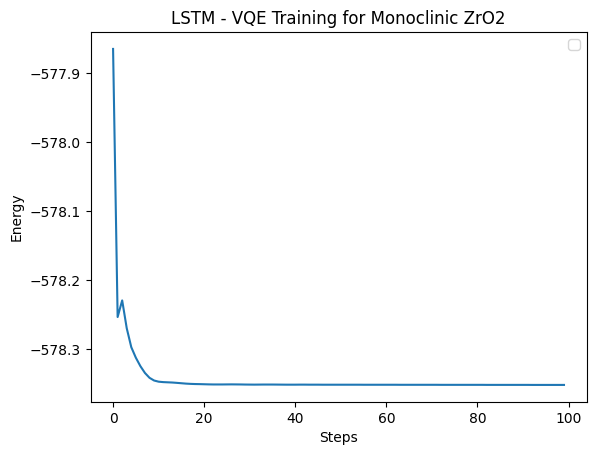

Estimated ground state energy of Monoclinic ZrO2: -578.3521728515625


In [13]:
# 绘制能量变化曲线
plt.figure()
plt.plot(energy_data)
plt.title('LSTM - VQE Training for Monoclinic ZrO2', fontsize=12)
plt.legend()
plt.xlabel('Steps', fontsize=10)
plt.ylabel('Energy', fontsize=10)
#plt.savefig('lstm_vqe_lih_energy.png')
plt.show()

print(f"Estimated ground state energy of Monoclinic ZrO2: {energy_data[-1]}")

In [14]:
-578.3521728515625

-578.3521728515625

In [15]:
print('L5_LSTM=',energy_data)

L5_LSTM= [-577.86444, -578.2536, -578.2295, -578.2699, -578.2974, -578.3127, -578.32495, -578.33484, -578.34186, -578.34576, -578.3475, -578.3481, -578.3484, -578.3487, -578.3492, -578.34973, -578.3503, -578.35065, -578.3509, -578.351, -578.3512, -578.3514, -578.3515, -578.3515, -578.3515, -578.35144, -578.3514, -578.35144, -578.3515, -578.3516, -578.3517, -578.35175, -578.3517, -578.3516, -578.3516, -578.3516, -578.3517, -578.35175, -578.3518, -578.3518, -578.3518, -578.35175, -578.35175, -578.3518, -578.3518, -578.3518, -578.35187, -578.35187, -578.35187, -578.35187, -578.35187, -578.35187, -578.35187, -578.35187, -578.35187, -578.3519, -578.3519, -578.3519, -578.3519, -578.3519, -578.3519, -578.3519, -578.3519, -578.352, -578.352, -578.352, -578.352, -578.352, -578.352, -578.352, -578.352, -578.352, -578.35205, -578.35205, -578.35205, -578.35205, -578.35205, -578.35205, -578.35205, -578.35205, -578.35205, -578.35205, -578.3521, -578.3521, -578.3521, -578.3521, -578.3521, -578.3521, 

## bfgs 优化

In [6]:
ansatz_circuit, \
init_amplitudes, \
ansatz_parameter_names, \
hamiltonian_QubitOp, \
n_qubits, n_electrons = generate_uccsd(ZrO2d, threshold=-1,active_space_start=22, active_space_stop=27)

In [7]:
hartreefock_wfn_circuit = Circuit([X.on(i) for i in range(n_electrons)])
total_circuit = hartreefock_wfn_circuit + ansatz_circuit
total_circuit.summary()
print("Number of parameters: %d" % (len(ansatz_parameter_names)))

                           Circuit Summary                           
╭──────────────────────┬────────────────────────────────────────────╮
│ Info                 │ value                                      │
├──────────────────────┼────────────────────────────────────────────┤
│ Number of qubit      │ 10                                         │
├──────────────────────┼────────────────────────────────────────────┤
│ Total number of gate │ 6588                                       │
│ Barrier              │ 1440                                       │
│ Noise Channel        │ 0                                          │
│ Measurement          │ 0                                          │
├──────────────────────┼────────────────────────────────────────────┤
│ Parameter gate       │ 360                                        │
│ 27 ansatz parameters │ p0, p6, p1, p7, p2, p8, p3, p9, p4, p10... │
╰──────────────────────┴────────────────────────────────────────────╯

Number of parameters: 27


In [8]:
sim = Simulator('mqvector', total_circuit.n_qubits)
molecule_pqc = sim.get_expectation_with_grad(Hamiltonian(hamiltonian_QubitOp), total_circuit)

In [55]:
import numpy as np

n_params = len(total_circuit.params_name)
#p0 = np.zeros(n_params)
p0 = np.random.uniform(0, 2*np.pi, n_params)
#f, g = molecule_pqc(p0)
#print("Energy: ", f, "\nshape: ", f.shape, '\n')
#print("Gradient: ", g, "\nshape: ", g.shape)

def fun(p0, molecule_pqc, energy_list=None):
    f, g = molecule_pqc(p0)
    f = np.real(f)[0, 0]
    g = np.real(g)[0, 0]
    if energy_list is not None:
        energy_list.append(f)
        if len(energy_list) % 5 == 0:
            print(f"Step: {len(energy_list)},\tenergy: {f}")
    return f, g

In [56]:
from scipy.optimize import minimize

energy_list = []
res = minimize(fun, p0, args=(molecule_pqc, energy_list), method='bfgs', jac=True)

Step: 5,	energy: -577.6578770888236
Step: 10,	energy: -577.7240947249167
Step: 15,	energy: -578.3138429849544
Step: 20,	energy: -578.3296611779997
Step: 25,	energy: -578.3300738212449
Step: 30,	energy: -578.3301478424296
Step: 35,	energy: -578.3301956405609
Step: 40,	energy: -578.3302256448022
Step: 45,	energy: -578.3304455347359
Step: 50,	energy: -578.3308258232704
Step: 55,	energy: -578.330871420317
Step: 60,	energy: -578.3309908411356
Step: 65,	energy: -578.3311078941068
Step: 70,	energy: -578.3311256251696
Step: 75,	energy: -578.331164136257
Step: 80,	energy: -578.33116913169
Step: 85,	energy: -578.3312449813449
Step: 90,	energy: -578.331300489389
Step: 95,	energy: -578.3313252122075
Step: 100,	energy: -578.3313670387695
Step: 105,	energy: -578.3313686765861
Step: 110,	energy: -578.3313834656365
Step: 115,	energy: -578.3313878461605
Step: 120,	energy: -578.331400168229
Step: 125,	energy: -578.3314137138875
Step: 130,	energy: -578.3314202204426
Step: 135,	energy: -578.3314407807853


/tmp/ipykernel_1081936/443170907.py:5: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


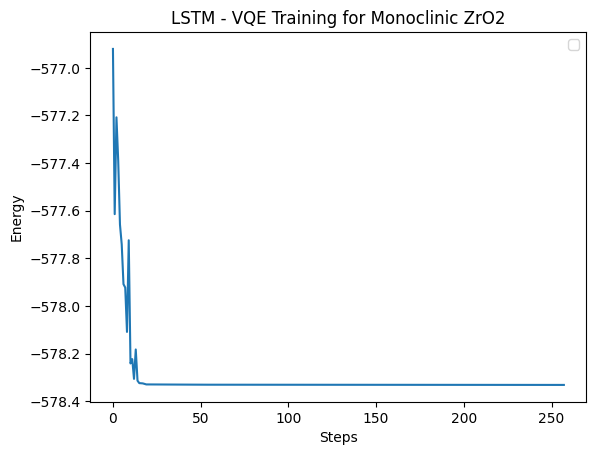

Estimated ground state energy of Monoclinic ZrO2: -578.3317786134453


In [57]:
# 绘制能量变化曲线
plt.figure()
plt.plot(energy_list)
plt.title('LSTM - VQE Training for Monoclinic ZrO2', fontsize=12)
plt.legend()
plt.xlabel('Steps', fontsize=10)
plt.ylabel('Energy', fontsize=10)
#plt.savefig('lstm_vqe_lih_energy.png')
plt.show()

print(f"Estimated ground state energy of Monoclinic ZrO2: {energy_list[-1]}")

In [12]:
-578.3316879999263

-578.3316879999263

In [13]:
print('L5_bfgs=',energy_list)

L5_bfgs= [-576.8484141009152, -576.9085808765574, -577.2623529713118, -577.1636058091427, -576.9991300781612, -577.2879147622871, -577.4797328831918, -577.3671593519646, -577.5587980789729, -577.5886223770452, -577.6405490214756, -577.7222488798578, -577.7250669033724, -577.7691920234945, -577.7987171695764, -577.8365591136821, -577.9003431227843, -577.9355786732681, -577.9506424339621, -577.9948672255354, -578.0690460562118, -578.1851338817291, -578.091772111817, -578.2407764236281, -578.2892702482379, -578.2780352656413, -578.312103182436, -578.3107238380543, -578.3235522110681, -578.3115992047939, -578.326477070371, -578.3247334111059, -578.3272613020637, -578.3282561606111, -578.3282302892858, -578.3287498469491, -578.3294589069158, -578.3302734371839, -578.3306390223146, -578.3307354300704, -578.3307687219151, -578.3307889920229, -578.3308224311064, -578.3308670386787, -578.3308907538379, -578.3309076029519, -578.3309161579746, -578.3309195743795, -578.330921356116, -578.330923693

## 优化 L-BFGS-B

In [58]:
ansatz_circuit, \
init_amplitudes, \
ansatz_parameter_names, \
hamiltonian_QubitOp, \
n_qubits, n_electrons = generate_uccsd(ZrO2d, threshold=-1,active_space_start=22, active_space_stop=27)

In [65]:
 n_electrons

4

In [59]:
hartreefock_wfn_circuit = Circuit([X.on(i) for i in range(n_electrons)])
total_circuit = hartreefock_wfn_circuit + ansatz_circuit
total_circuit.summary()
print("Number of parameters: %d" % (len(ansatz_parameter_names)))

                           Circuit Summary                           
╭──────────────────────┬────────────────────────────────────────────╮
│ Info                 │ value                                      │
├──────────────────────┼────────────────────────────────────────────┤
│ Number of qubit      │ 10                                         │
├──────────────────────┼────────────────────────────────────────────┤
│ Total number of gate │ 6588                                       │
│ Barrier              │ 1440                                       │
│ Noise Channel        │ 0                                          │
│ Measurement          │ 0                                          │
├──────────────────────┼────────────────────────────────────────────┤
│ Parameter gate       │ 360                                        │
│ 27 ansatz parameters │ p0, p6, p1, p7, p2, p8, p3, p9, p4, p10... │
╰──────────────────────┴────────────────────────────────────────────╯

Number of parameters: 27


In [60]:
sim = Simulator('mqvector', total_circuit.n_qubits)
molecule_pqc = sim.get_expectation_with_grad(Hamiltonian(hamiltonian_QubitOp), total_circuit)

In [74]:
import numpy as np

n_params = len(total_circuit.params_name)
#p0 = np.zeros(n_params)
p0 = np.random.uniform(0, 2*np.pi, n_params)
#f, g = molecule_pqc(p0)
#print("Energy: ", f, "\nshape: ", f.shape, '\n')
#print("Gradient: ", g, "\nshape: ", g.shape)

def fun(p0, molecule_pqc, energy_list=None):
    f, g = molecule_pqc(p0)
    f = np.real(f)[0, 0]
    g = np.real(g)[0, 0]
    if energy_list is not None:
        energy_list.append(f)
        if len(energy_list) % 5 == 0:
            print(f"Step: {len(energy_list)},\tenergy: {f}")
    return f, g

In [75]:
from scipy.optimize import minimize

energy_list = []
res = minimize(fun, p0, args=(molecule_pqc, energy_list), method='L-BFGS-B', jac=True)

Step: 5,	energy: -577.6437458444132
Step: 10,	energy: -577.9596724124935
Step: 15,	energy: -578.273585574743
Step: 20,	energy: -578.322499215128
Step: 25,	energy: -578.3279770456346
Step: 30,	energy: -578.3315547800944
Step: 35,	energy: -578.3318640434709
Step: 40,	energy: -578.3322503256393
Step: 45,	energy: -578.3326130960806
Step: 50,	energy: -578.3344711298228
Step: 55,	energy: -578.334985487667
Step: 60,	energy: -578.33502609201
Step: 65,	energy: -578.3350491690029


/tmp/ipykernel_1081936/443170907.py:5: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


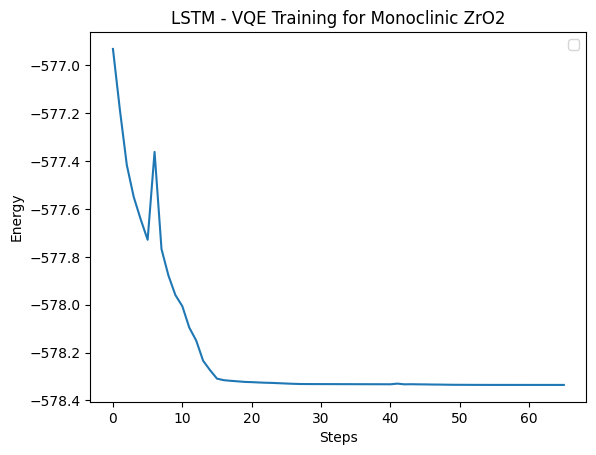

Estimated ground state energy of Monoclinic ZrO2: -578.3350501006697


In [76]:
# 绘制能量变化曲线
plt.figure()
plt.plot(energy_list)
plt.title('LSTM - VQE Training for Monoclinic ZrO2', fontsize=12)
plt.legend()
plt.xlabel('Steps', fontsize=10)
plt.ylabel('Energy', fontsize=10)
#plt.savefig('lstm_vqe_lih_energy.png')
plt.show()

print(f"Estimated ground state energy of Monoclinic ZrO2: {energy_list[-1]}")

In [72]:
-578.330337410853

-578.330337410853

In [73]:
print('L5_L-BFGS-B=',energy_list)

L5_L-BFGS-B= [-576.8672596577064, -577.2452665551242, -577.3956066408757, -577.3423270732616, -577.5464737593416, -577.6491914021758, -577.1520232029791, -577.7467752332146, -577.5863762685169, -577.8764451591658, -578.0463280944468, -578.2461282722129, -578.2643310491377, -578.3088396897693, -578.3193352896355, -578.3238242153298, -578.3259383993008, -578.3281150536011, -578.3293957002005, -578.330167458597, -578.3302828800577, -578.3303161465515, -578.3303267681672, -578.3303368519441, -578.330337410853]


In [78]:
print('L5_L_BFGS_B=',energy_list)

L5_L_BFGS_B= [-576.9319567787984, -577.1861862460457, -577.417171813154, -577.5504564780766, -577.6437458444132, -577.7290172910118, -577.3620250578823, -577.7681075445872, -577.8783016704438, -577.9596724124935, -578.0061815680099, -578.0954473798038, -578.1497025449369, -578.234120084689, -578.273585574743, -578.3088787422391, -578.3153236289318, -578.3179545638804, -578.3201562548785, -578.322499215128, -578.3234323270863, -578.3248223214575, -578.3259358620919, -578.3267261524009, -578.3279770456346, -578.3292910525934, -578.3303787269086, -578.3311974204394, -578.3314149405512, -578.3315547800944, -578.3315975410192, -578.3316397426588, -578.3317060963225, -578.3318261985374, -578.3318640434709, -578.3320037410411, -578.3320546909846, -578.332126708477, -578.3321434505883, -578.3322503256393, -578.3323932768332, -578.3296319660243, -578.3325363630926, -578.3321417877797, -578.3326130960806, -578.3328610406434, -578.3334118491479, -578.3336460432809, -578.3340754038753, -578.334471

## 优化 CG

In [119]:
import numpy as np

n_params = len(total_circuit.params_name)
#p0 = np.zeros(n_params)
p0 = np.random.uniform(0, 2*np.pi, n_params)
#f, g = molecule_pqc(p0)
#print("Energy: ", f, "\nshape: ", f.shape, '\n')
#print("Gradient: ", g, "\nshape: ", g.shape)

def fun(p0, molecule_pqc, energy_list=None):
    f, g = molecule_pqc(p0)
    f = np.real(f)[0, 0]
    g = np.real(g)[0, 0]
    if energy_list is not None:
        energy_list.append(f)
        if len(energy_list) % 5 == 0:
            print(f"Step: {len(energy_list)},\tenergy: {f}")
    return f, g

In [120]:
from scipy.optimize import minimize

energy_list = []
res = minimize(fun, p0, args=(molecule_pqc, energy_list), method='CG', jac=True)

Step: 5,	energy: -577.3036979792294
Step: 10,	energy: -577.571536834508
Step: 15,	energy: -577.7385276879744
Step: 20,	energy: -578.1831399916753
Step: 25,	energy: -578.1500220615409
Step: 30,	energy: -578.3186740182468
Step: 35,	energy: -578.3282093426442
Step: 40,	energy: -578.3289661787711
Step: 45,	energy: -578.3297864630916
Step: 50,	energy: -578.3301032065579
Step: 55,	energy: -578.3301799893413
Step: 60,	energy: -578.3303538485046
Step: 65,	energy: -578.3304317975756
Step: 70,	energy: -578.3304512858033
Step: 75,	energy: -578.3304727691519
Step: 80,	energy: -578.3304788488522
Step: 85,	energy: -578.33049403526
Step: 90,	energy: -578.3305180931665
Step: 95,	energy: -578.3305258636007
Step: 100,	energy: -578.330528285194
Step: 105,	energy: -578.3305286931395
Step: 110,	energy: -578.3305312761801
Step: 115,	energy: -578.3305573283568
Step: 120,	energy: -578.3305450831543
Step: 125,	energy: -578.330594484532
Step: 130,	energy: -578.3306072700864
Step: 135,	energy: -578.3306121038156

/tmp/ipykernel_1081936/443170907.py:5: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


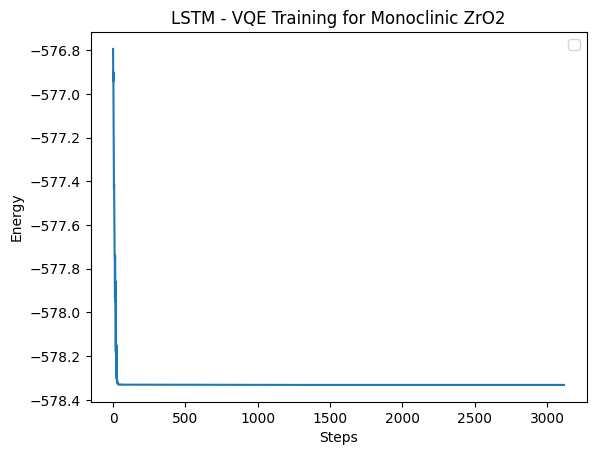

Estimated ground state energy of Monoclinic ZrO2: -578.3316595923467


In [121]:
# 绘制能量变化曲线
plt.figure()
plt.plot(energy_list)
plt.title('LSTM - VQE Training for Monoclinic ZrO2', fontsize=12)
plt.legend()
plt.xlabel('Steps', fontsize=10)
plt.ylabel('Energy', fontsize=10)
#plt.savefig('lstm_vqe_lih_energy.png')
plt.show()

print(f"Estimated ground state energy of Monoclinic ZrO2: {energy_list[-1]}")

In [84]:
-578.3501168141656

-578.3501168141656

In [122]:
print('L5_CG=',energy_list)

L5_CG= [-576.7936152855102, -576.9429489548816, -576.9000165163533, -577.0636750840322, -577.3036979792294, -577.3653493045141, -577.4308587181959, -577.4115437768703, -577.4991560852667, -577.571536834508, -577.6768019968691, -577.7559661120605, -577.7672294693423, -577.9328214060781, -577.7385276879744, -577.9491098593228, -577.8557037251335, -578.0242209444378, -578.147210029667, -578.1831399916753, -577.9412682656377, -578.2199999191324, -578.2677188366937, -578.2989313290745, -578.1500220615409, -578.3031779499005, -578.3101363318812, -578.3144781489794, -578.30635100171, -578.3186740182468, -578.3235515469947, -578.3203921278694, -578.325436525685, -578.3267937765783, -578.3282093426442, -578.3286800743704, -578.3290659185487, -578.3285562341781, -578.3294001661778, -578.3289661787711, -578.329460538205, -578.3295633174738, -578.3296547875274, -578.3297550441137, -578.3297864630916, -578.3299675447862, -578.3299563991252, -578.3300563594963, -578.3300645381595, -578.3301032065579

## 优化 SLSQP

In [127]:
import numpy as np

n_params = len(total_circuit.params_name)
#p0 = np.zeros(n_params)
p0 = np.random.uniform(0, 2*np.pi, n_params)
#f, g = molecule_pqc(p0)
#print("Energy: ", f, "\nshape: ", f.shape, '\n')
#print("Gradient: ", g, "\nshape: ", g.shape)

def fun(p0, molecule_pqc, energy_list=None):
    f, g = molecule_pqc(p0)
    f = np.real(f)[0, 0]
    g = np.real(g)[0, 0]
    if energy_list is not None:
        energy_list.append(f)
        if len(energy_list) % 5 == 0:
            print(f"Step: {len(energy_list)},\tenergy: {f}")
    return f, g

In [128]:
from scipy.optimize import minimize

energy_list = []
res = minimize(fun, p0, args=(molecule_pqc, energy_list), method='SLSQP', jac=True)

Step: 5,	energy: -577.256588382801
Step: 10,	energy: -577.0756511315424
Step: 15,	energy: -577.6598351870166
Step: 20,	energy: -578.3139618412115
Step: 25,	energy: -578.3271029133915
Step: 30,	energy: -578.3293513613157
Step: 35,	energy: -578.3301984204087


/tmp/ipykernel_1081936/443170907.py:5: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


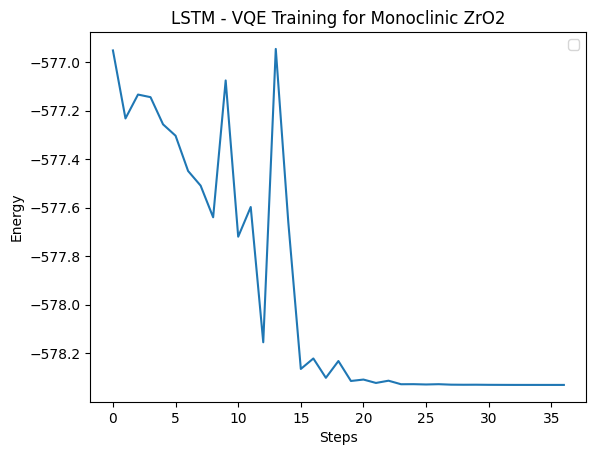

Estimated ground state energy of Monoclinic ZrO2: -578.3302055713592


In [129]:
# 绘制能量变化曲线
plt.figure()
plt.plot(energy_list)
plt.title('LSTM - VQE Training for Monoclinic ZrO2', fontsize=12)
plt.legend()
plt.xlabel('Steps', fontsize=10)
plt.ylabel('Energy', fontsize=10)
#plt.savefig('lstm_vqe_lih_energy.png')
plt.show()

print(f"Estimated ground state energy of Monoclinic ZrO2: {energy_list[-1]}")

In [130]:
print('L5_SLSQP=',energy_list)

L5_SLSQP= [-576.9520405824644, -577.2322492366169, -577.133797289212, -577.1445728956185, -577.256588382801, -577.3034917954297, -577.4487149449179, -577.5090988443732, -577.6395257389277, -577.0756511315424, -577.7194777651928, -577.5971449164342, -578.1545253885859, -576.9457962857625, -577.6598351870166, -578.2644284019652, -578.2212363246114, -578.3008960015578, -578.2317668315814, -578.3139618412115, -578.3081064321972, -578.3220818553483, -578.3128122029154, -578.3273916857066, -578.3271029133915, -578.3283796125415, -578.3271993359093, -578.3291585370696, -578.3295192814472, -578.3293513613157, -578.3298114295269, -578.3300053530909, -578.3301426786521, -578.3301825744534, -578.3301984204087, -578.3302036604755, -578.3302055713592]
